# Estatísticas das Saídas do Treino-Dengue

In [2]:
import pandas as pd

predicoes = pd.read_csv('predicoes.csv', header=None)
probas = pd.read_csv('probabilidades.csv', header=None)

dengue_df  = pd.read_csv('../../database/Dengue.csv')
malaria_df = pd.read_csv('../../database/Malaria.csv')
shared_df  = pd.read_csv('../../database/Shared.csv')

df_dengue_teste = dengue_df[dengue_df['tipo'] == 'teste']

y_test  = df_dengue_teste['Result']
y_val   = malaria_df['Result']
y_shared= shared_df['Result']

 Model | Acura | Preci | Recal | F1-sco |   MCC  |   AUC
knn-te | 80.16 | 82.67 | 82.42 | 0.8015 | 0.6510 | 0.8661
knn-va | 64.67 | 67.51 | 65.24 | 0.6368 | 0.3267 | 0.6953
knn-sh | 51.65 | 58.77 | 51.65 | 0.3935 | 0.0761 | 0.5123
rfo-te | 88.59 | 88.88 | 89.86 | 0.8855 | 0.7873 | 0.9226
rfo-va | 62.44 | 62.43 | 62.28 | 0.6225 | 0.2471 | 0.6995
rfo-sh | 47.93 | 47.93 | 47.93 | 0.4792 | -0.0413 | 0.5387
svm-te | 84.22 | 84.44 | 85.31 | 0.8415 | 0.6975 | 0.8805
svm-va | 63.38 | 63.84 | 63.60 | 0.6328 | 0.2744 | 0.6761
svm-sh | 54.96 | 57.80 | 54.96 | 0.5045 | 0.1244 | 0.5817
xgb-te | 89.06 | 89.38 | 90.36 | 0.8902 | 0.7974 | 0.9293
xgb-va | 63.03 | 63.13 | 62.79 | 0.6267 | 0.2592 | 0.7081
xgb-sh | 50.21 | 50.21 | 50.21 | 0.4977 | 0.0042 | 0.5405


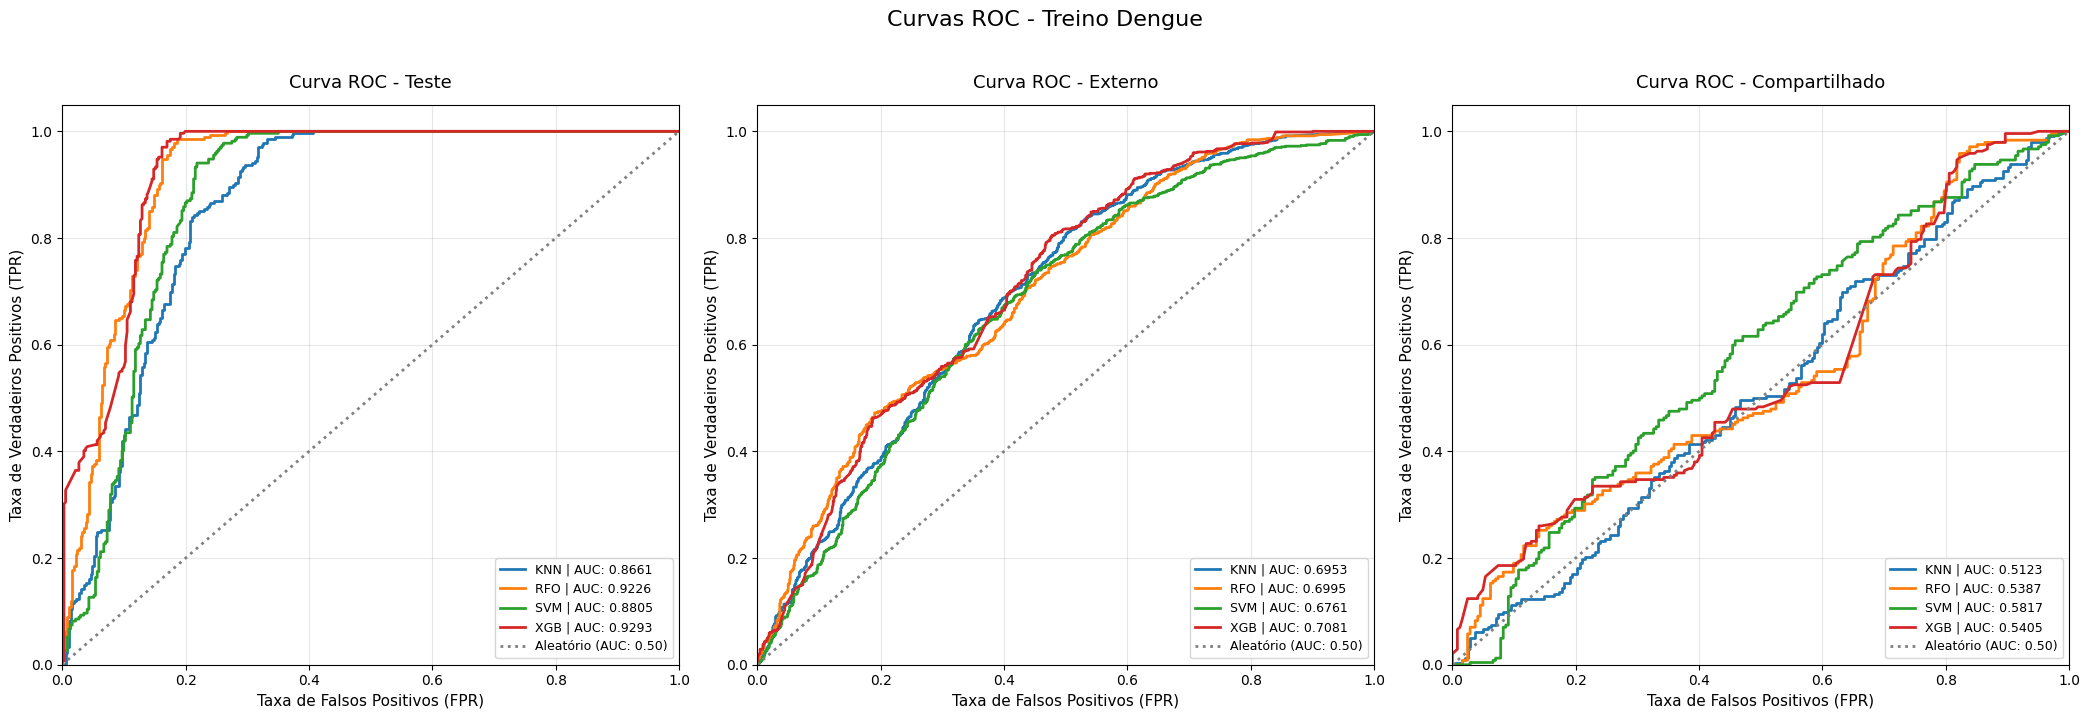

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             matthews_corrcoef, confusion_matrix, roc_curve)

print(' Model | Acura | Preci | Recal | F1-sco |   MCC  |   AUC')

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

eixos = {
    'teste':  axes[0],
    'valid':  axes[1],
    'shared': axes[2],
}

titulos = {
    'teste':  'Curva ROC - Teste',
    'valid':  'Curva ROC - Externo',
    'shared': 'Curva ROC - Compartilhado',
}

for i in range(len(predicoes)):
    y_pred  = predicoes.iloc[i, 2:].dropna().astype(int)
    y_proba = probas.iloc[i, 2:].dropna().astype(float)
    
    nome_modelo = predicoes.iloc[i, 0]

    if predicoes.iloc[i, 1] == 'teste':
        y = y_test.astype(int)
        tipo = 'te'
        chave = 'teste'
        nome_legenda = 'Teste'
    elif predicoes.iloc[i, 1] == 'shared':
        y = y_shared.astype(int)
        tipo = 'sh'
        chave = 'shared'
        nome_legenda = 'Compart.'
    else:
        y = y_val.astype(int)
        tipo = 'va'
        chave = 'valid'
        nome_legenda = 'Valid'

    # Métricas originais
    acuracia = accuracy_score(y, y_pred) * 100
    precisao = precision_score(y, y_pred, average='macro', zero_division=0) * 100
    recall   = recall_score(y, y_pred, average='macro', zero_division=0) * 100
    f1       = f1_score(y, y_pred, average='macro', zero_division=0)
    mcc      = matthews_corrcoef(y, y_pred)
    auc      = roc_auc_score(y, y_proba)

    print(f'{nome_modelo}-{tipo} | {acuracia:.2f} | {precisao:.2f} | {recall:.2f} | {f1:.4f} | {mcc:.4f} | {auc:.4f}')

    # Calcula a curva ROC e plota no subplot correspondente
    fpr, tpr, limiares = roc_curve(y, y_proba)
    ax = eixos[chave]
    ax.plot(fpr, tpr, lw=2, label=f'{nome_modelo.upper()} | AUC: {auc:.4f}')

# Configura cada subplot individualmente
for chave, ax in eixos.items():
    ax.plot([0, 1], [0, 1], color='gray', lw=2, linestyle=':', label='Aleatório (AUC: 0.50)')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('Taxa de Falsos Positivos (FPR)', fontsize=11)
    ax.set_ylabel('Taxa de Verdadeiros Positivos (TPR)', fontsize=11)
    ax.set_title(titulos[chave], fontsize=13, pad=12)
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Curvas ROC - Treino Dengue', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()